<a href="https://colab.research.google.com/github/Tanushkasharma04/Data-Analysis/blob/main/Copy_of_Salary_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
abdallahwagih_company_employees_path = kagglehub.dataset_download('abdallahwagih/company-employees')

print('Data source import complete.')


100%|██████████| 68.2k/68.2k [00:00<00:00, 300kB/s]

Extracting files...
Data source import complete.


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os

Employees = os.path.join(abdallahwagih_company_employees_path, 'Employees.xlsx')
data = pd.read_excel(Employees)
data

,No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours
0,1,Ghadir,Hmshw,Male,2018-04-04,2,Quality Control,Egypt,West,1560,18720,3.0,1,0,183
1,2,Omar,Hishan,Male,2020-05-21,0,Quality Control,Saudi Arabia,West,3247,38964,1.0,0,5,198
2,3,Ailya,Sharaf,Female,2017-09-28,3,Major Mfg Projects,Saudi Arabia,West,2506,30072,2.0,0,3,192
3,4,Lwiy,Qbany,Male,2018-08-14,2,Manufacturing,United Arab Emirates,Main,1828,21936,3.0,0,0,7
4,5,Ahmad,Bikri,Male,2020-03-11,0,Manufacturing,Egypt,Main,970,11640,5.0,0,5,121
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
684,685,Sari,Hanna,Male,2020-05-26,0,Marketing,Lebanon,South,1452,17424,2.0,0,3,1
685,686,Eubayda,Kayd,Male,2020-06-03,0,Facilities/Engineering,Egypt,North,3237,38844,3.0,1,0,4
686,687,Khalil,Alkalu,Male,2017-07-11,3,Facilities/Engineering,Egypt,North,2819,33828,5.0,0,0,0
687,688,Muhamad,Shrbjy,Male,2018-05-30,2,Creative,Egypt,North,2069,24828,3.0,0,0,10


In [ ]:
data.head(3)

,No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours
0,1,Ghadir,Hmshw,Male,2018-04-04,2,Quality Control,Egypt,West,1560,18720,3.0,1,0,183
1,2,Omar,Hishan,Male,2020-05-21,0,Quality Control,Saudi Arabia,West,3247,38964,1.0,0,5,198
2,3,Ailya,Sharaf,Female,2017-09-28,3,Major Mfg Projects,Saudi Arabia,West,2506,30072,2.0,0,3,192


In [ ]:
data.tail(3)

,No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours
686,687,Khalil,Alkalu,Male,2017-07-11,3,Facilities/Engineering,Egypt,North,2819,33828,5.0,0,0,0
687,688,Muhamad,Shrbjy,Male,2018-05-30,2,Creative,Egypt,North,2069,24828,3.0,0,0,10
688,689,Abd Albasit,AlAhmar,Male,2020-08-05,0,IT,United Arab Emirates,North,2606,31272,5.0,0,0,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 689 entries, 0 to 688
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   No              689 non-null    int64         
 1   First Name      689 non-null    object        
 2   Last Name       689 non-null    object        
 3   Gender          689 non-null    object        
 4   Start Date      689 non-null    datetime64[ns]
 5   Years           689 non-null    int64         
 6   Department      689 non-null    object        
 7   Country         689 non-null    object        
 8   Center          689 non-null    object        
 9   Monthly Salary  689 non-null    int64         
 10  Annual Salary   689 non-null    int64         
 11  Job Rate        689 non-null    float64       
 12  Sick Leaves     689 non-null    int64         
 13  Unpaid Leaves   689 non-null    int64         
 14  Overtime Hours  689 non-null    int64         
dtypes: dat

In [ ]:
data.shape

(689, 15)

In [ ]:
data.isna()

,No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
684,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
685,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
686,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
687,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
data.isna().sum()

,0
No,0
First Name,0
Last Name,0
Gender,0
Start Date,0
Years,0
Department,0
Country,0
Center,0
Monthly Salary,0


In [ ]:
#data.dropna(inplace=True) for dropping NA values in the dataset.
# in this dataset there are no NA values.

In [ ]:
data.duplicated().sum()
# data.drop_duplicates(inplace = True) for dropping duplicates.

np.int64(0)

In [ ]:
data.head(3)

,No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours
0,1,Ghadir,Hmshw,Male,2018-04-04,2,Quality Control,Egypt,West,1560,18720,3.0,1,0,183
1,2,Omar,Hishan,Male,2020-05-21,0,Quality Control,Saudi Arabia,West,3247,38964,1.0,0,5,198
2,3,Ailya,Sharaf,Female,2017-09-28,3,Major Mfg Projects,Saudi Arabia,West,2506,30072,2.0,0,3,192


In [ ]:
data.value_counts()

,,,,,,,,,,,,,,,count
No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours,
689,Abd Albasit,AlAhmar,Male,2020-08-05,0,IT,United Arab Emirates,North,2606,31272,5.0,0,0,0,1
673,Muhamad,Sharif Aldaghly,Male,2018-01-04,3,IT,Egypt,West,3257,39084,3.0,0,0,6,1
672,Jihan,Nadir,Female,2019-04-18,1,Facilities/Engineering,United Arab Emirates,North,1045,12540,5.0,6,0,4,1
671,Ayly,Bahriin,Male,2017-09-14,3,Professional Training Group,Saudi Arabia,Main,1232,14784,5.0,3,0,10,1
670,Dania,Earmush,Female,2019-12-01,1,Product Development,United Arab Emirates,Main,2760,33120,1.0,6,6,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6,Muhamad,Zueitr,Male,2016-02-02,4,Product Development,Saudi Arabia,North,2332,27984,3.0,3,0,8,1
5,Ahmad,Bikri,Male,2020-03-11,0,Manufacturing,Egypt,Main,970,11640,5.0,0,5,121,1
4,Lwiy,Qbany,Male,2018-08-14,2,Manufacturing,United Arab Emirates,Main,1828,21936,3.0,0,0,7,1


In [ ]:
import matplotlib.pyplot as plt

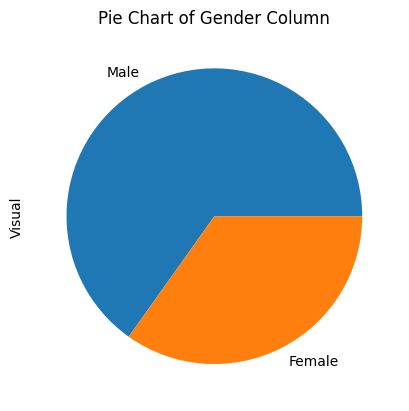

In [ ]:
data["Gender"].value_counts().sort_values(ascending=False).plot(kind="pie")
plt.title("Pie Chart of Gender Column")
plt.ylabel("Visual")
plt.show()

In [ ]:
data.head(2)

,No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours
0,1,Ghadir,Hmshw,Male,2018-04-04,2,Quality Control,Egypt,West,1560,18720,3.0,1,0,183
1,2,Omar,Hishan,Male,2020-05-21,0,Quality Control,Saudi Arabia,West,3247,38964,1.0,0,5,198


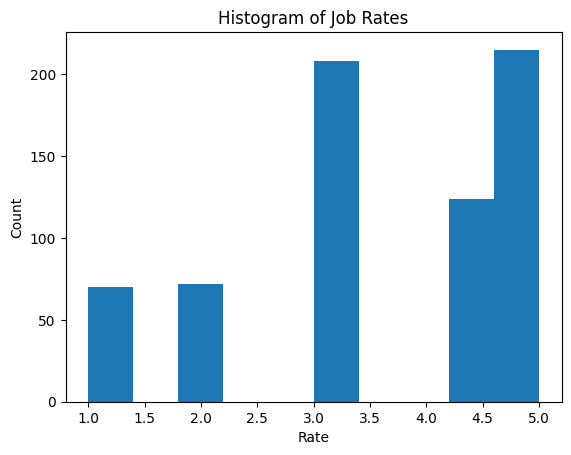

In [ ]:
plt.hist(data["Job Rate"])
plt.title("Histogram of Job Rates")
plt.xlabel("Rate")
plt.ylabel("Count")
plt.show()


In [ ]:
data["Job Rate"].describe()

,Job Rate
count,689.000000
mean,3.586357
std,1.350125
min,1.000000
25%,3.000000
50%,3.000000
75%,5.000000
max,5.000000


In [ ]:
data.head()

,No,First Name,Last Name,Gender,Start Date,Years,Department,Country,Center,Monthly Salary,Annual Salary,Job Rate,Sick Leaves,Unpaid Leaves,Overtime Hours
0,1,Ghadir,Hmshw,Male,2018-04-04,2,Quality Control,Egypt,West,1560,18720,3.0,1,0,183
1,2,Omar,Hishan,Male,2020-05-21,0,Quality Control,Saudi Arabia,West,3247,38964,1.0,0,5,198
2,3,Ailya,Sharaf,Female,2017-09-28,3,Major Mfg Projects,Saudi Arabia,West,2506,30072,2.0,0,3,192
3,4,Lwiy,Qbany,Male,2018-08-14,2,Manufacturing,United Arab Emirates,Main,1828,21936,3.0,0,0,7
4,5,Ahmad,Bikri,Male,2020-03-11,0,Manufacturing,Egypt,Main,970,11640,5.0,0,5,121


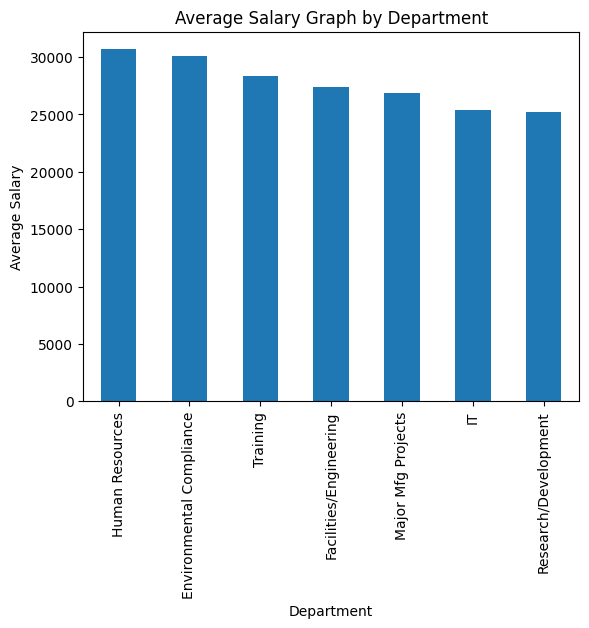

In [ ]:
data.groupby("Department")["Annual Salary"].mean().sort_values(ascending=False).head(7).plot(kind="bar")
plt.title("Average Salary Graph by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.show()

In [ ]:
data['Department'].value_counts()

,count
Department,
Manufacturing,140
Quality Control,89
Account Management,84
Quality Assurance,67
Facilities/Engineering,58
Marketing,48
IT,40
Product Development,34
Sales,20


In [ ]:
data.groupby("Center")["Monthly Salary"].mean().sort_values(ascending=False)

,Monthly Salary
Center,
East,2274.021277
West,2068.672269
North,2064.811594
Main,2054.776892
South,1981.153846


In [ ]:
data["Country"].unique()

array(['Egypt', 'Saudi Arabia', 'United Arab Emirates', 'Syria',
       'Lebanon'], dtype=object)

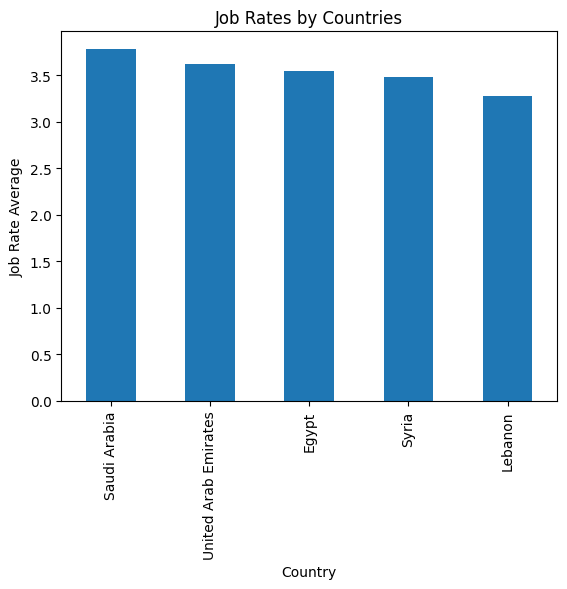

In [ ]:
data.groupby("Country")["Job Rate"].mean().sort_values(ascending=False).plot(kind = "bar")
plt.title("Job Rates by Countries")
plt.xlabel("Country")
plt.ylabel("Job Rate Average")
plt.show()

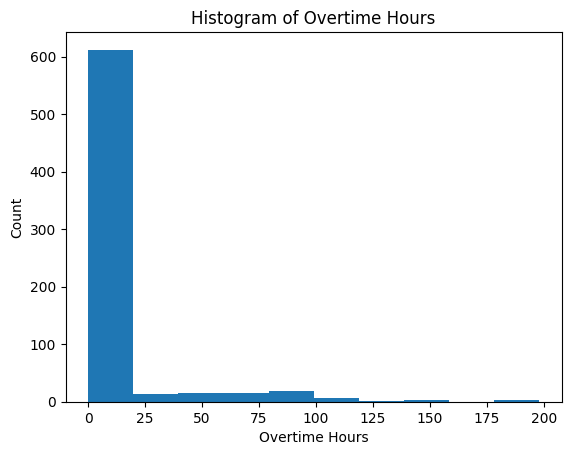

In [ ]:
plt.hist(data["Overtime Hours"])
plt.title("Histogram of Overtime Hours")
plt.xlabel("Overtime Hours")
plt.ylabel("Count")
plt.show()

In [ ]:
data['Overtime Hours'].describe()

,Overtime Hours
count,689.000000
mean,13.702467
std,25.692049
min,0.000000
25%,3.000000
50%,7.000000
75%,10.000000
max,198.000000


In [ ]:
data["Annual Salary"].describe()

,Annual Salary
count,689.000000
mean,24818.420900
std,9159.470878
min,8436.000000
25%,17232.000000
50%,24924.000000
75%,32184.000000
max,41400.000000


In [ ]:
import streamlit as st
import numpy as np
import joblib
import subprocess
import os

# Create a Python file for the Streamlit app
streamlit_app_code = """
import streamlit as st
import numpy as np
import joblib

st.title("Salary Prediction App")
st.divider()
st.write("With this app you can get estimations of the salaries of Employee ")

years = st.number_input("Years of Experience", value=1, step=1, min_value=0)
jobrate = st.number_input("Job Rate", value=3.5, step=0.5, min_value=0.0)

X = [years, jobrate]
model = joblib.load("linearmodel.pkl") # Ensure this file is accessible
st.divider()

predict = st.button("Press the button for salary prediction")
st.divider()

if predict:
  st.balloons()
  X1 = np.array([X]).reshape(1, -1) # Reshape for single prediction
  prediction = model.predict(X1)
  st.write(f"Salary prediction is {prediction[0]:.2f}")
else:
  st.write("Please press the button for the app to make the prediction")
"""

with open("streamlit_app.py", "w") as f:
    f.write(streamlit_app_code)

# Install pyngrok if not already installed
!pip install pyngrok -q

# Set Streamlit server to run on a specific port
# This is important for ngrok to tunnel to it
os.environ['STREAMLIT_SERVER_PORT'] = '8501'

# Run Streamlit in the background and create a ngrok tunnel
from pyngrok import ngrok, conf

# Terminate any previous ngrok tunnels
ngrok.kill()

# Authtoken setup
# You need to replace 'YOUR_NGROK_AUTHTOKEN' with your actual ngrok authtoken.
# Sign up for an account at https://dashboard.ngrok.com/signup
# Get your authtoken from https://dashboard.ngrok.com/get-started/your-authtoken
# conf.get_default().auth_token = "YOUR_NGROK_AUTHTOKEN"

# IMPORTANT: Make sure to replace "YOUR_NGROK_AUTHTOKEN" below with your actual token.
# Example: ngrok.set_auth_token("2P7yYxYxYxYxYxYxYxYxYxYxYxYxYxYxYxYxYxYxY")
ngrok_auth_token = "39KvkCyqBZ6UiZP2qmlwU3da9O7_7d6DcctLrVrRgvdnpjG3q" # <---- REPLACE THIS WITH YOUR TOKEN

if ngrok_auth_token == "YOUR_NGROK_AUTHTOKEN":
    print("Please get your ngrok authtoken from https://dashboard.ngrok.com/get-started/your-authtoken and replace 'YOUR_NGROK_AUTHTOKEN' in the code.")
else:
    ngrok.set_auth_token(ngrok_auth_token)
    # Start Streamlit in the background
    streamlit_process = subprocess.Popen(["streamlit", "run", "streamlit_app.py", "--server.port", os.environ['STREAMLIT_SERVER_PORT'], "--server.headless", "true"])

    # Create a ngrok tunnel to the Streamlit app port
    public_url = ngrok.connect(int(os.environ['STREAMLIT_SERVER_PORT']))
    print(f"Your Streamlit app is live at: {public_url}")

Your Streamlit app is live at: NgrokTunnel: "https://caridad-regardant-thegnly.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
x=data[["Years","Job Rate"]]
y=data["Annual Salary"]

In [ ]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(x,y, test_size= 0.2)

In [ ]:
len(X_train)

551

In [ ]:
len(X_test)

138

In [ ]:
len(y_train)

551

In [ ]:
x

,Years,Job Rate
0,2,3.0
1,0,1.0
2,3,2.0
3,2,3.0
4,0,5.0
...,...,...
684,0,2.0
685,0,3.0
686,3,5.0
687,2,3.0


In [ ]:
from sklearn.linear_model import LinearRegression


In [ ]:
lr = LinearRegression()

In [ ]:
lr.fit(X_train,y_train)

LinearRegression()

In [ ]:
predslr = lr.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error

In [ ]:
mean_absolute_error(predslr,y_test)

7708.002635603581

In [ ]:
x

,Years,Job Rate
0,2,3.0
1,0,1.0
2,3,2.0
3,2,3.0
4,0,5.0
...,...,...
684,0,2.0
685,0,3.0
686,3,5.0
687,2,3.0


In [ ]:
import joblib
joblib.dump(lr,"linearmodel.pkl")

['linearmodel.pkl']

In [ ]:
!pip install streamlit
import streamlit as st
import numpy as np
import joblib

st.title("Salary Prediction App")
st.divider()
st.write("With this app you can get estimations of the salaries of Employee ")
years = st.number_input("Years of Experience", value=1, step=1, min_value=0)
jobrate = st.number_input("Job Rate", value=3.5, step=0.5, min_value=0.0)
X = [years, jobrate]
model = joblib.load("linearmodel.pkl")
st.divider()
predict = st.button("Press the button for salary prediction")
st.divider()
if predict:
  st.balloons()
  X1 = np.array([X])
  prediction = model.predict(X1)
  st.write(f"Salary prediction is {prediction[0]:.2f}")
else:
  "Please press button for app to make the prediction"

2026-09-10 13:09:21.023 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-10 13:09:21.026 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-10 13:09:21.027 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-10 13:09:21.028 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-10 13:09:21.030 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-10 13:09:21.031 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-10 13:09:21.032 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-10 13:09:21.034 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar